<a href="https://colab.research.google.com/github/murtaza-aiml/python_ai_ml/blob/main/random_forest_algrthm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Random Forest Evaluation ===
Out-of-Bag (OOB) Internal Score: 83.3%
Hidden Test Set Accuracy:        75.0%

=== Classification Report ===
              precision    recall  f1-score   support

  Hadron (0)       0.50      1.00      0.67         1
   Gamma (1)       1.00      0.67      0.80         3

    accuracy                           0.75         4
   macro avg       0.75      0.83      0.73         4
weighted avg       0.88      0.75      0.77         4

New Signal Prediction: Gamma-Ray Signal (1) (88% of trees agreed)


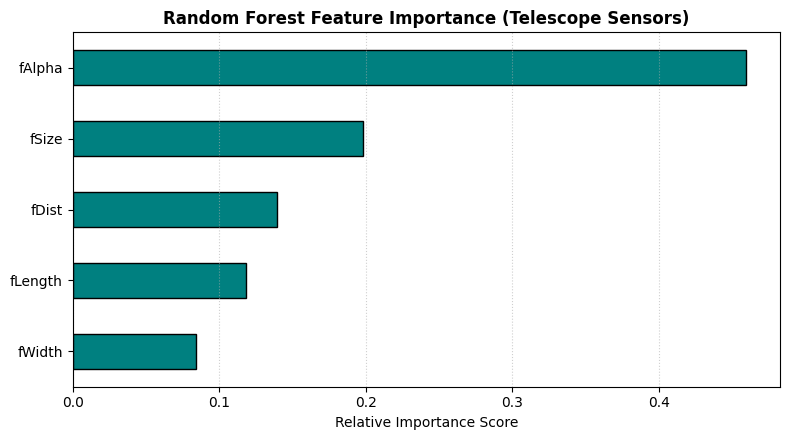

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# ==========================================
# === 1. SETUP TELESCOPE SAMPLE DATASET  ===
# ==========================================
# Features from the MAGIC Gamma Telescope dataset
data = {
    'fLength': [28.79, 31.60, 162.05, 23.81, 75.13, 51.62, 48.24, 26.78, 96.23, 46.76, 62.77, 18.85, 110.45, 34.12, 88.90, 21.50],
    'fWidth':  [16.00, 11.72, 136.03, 9.57,  30.92, 21.15, 17.35, 13.84, 46.51, 15.19, 29.91, 9.58,  52.10, 14.20, 41.30, 10.15],
    'fSize':   [2.64,  2.51,  4.06,   2.33,  3.16,  2.90,  3.03,  2.46,  3.26,  2.57,  3.33,  2.31,  3.55,  2.60,  3.18,  2.40],
    'fAlpha':  [40.09, 6.39,  76.96,  10.44, 4.64,  3.61,  8.53,  22.96, 43.14, 1.29,  33.76, 16.98, 55.20, 7.80,  39.40, 11.20],
    'fDist':   [81.88, 205.26,256.78, 116.73,356.46,238.09,180.93,145.53,248.29,102.28,302.78,114.64,275.40,190.10,260.50,125.80],
    'class':   ['g',   'g',   'h',    'g',   'g',   'g',   'g',   'h',   'h',   'g',   'h',   'g',   'h',   'g',   'h',   'g']
}

df = pd.DataFrame(data)

# Convert text labels ('g' = Gamma-ray, 'h' = Hadron noise) into binary numbers (1 and 0)
df['class'] = df['class'].map({'g': 1, 'h': 0})

X = df.drop(columns=['class'])
y = df['class']


# ==========================================
# === 2. TRAIN / TEST SPLIT              ===
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)


# ==========================================
# === 3. TRAIN RANDOM FOREST MODEL       ===
# ==========================================
# n_estimators=100 builds 100 trees; oob_score=True tests on the 36.8% left-out rows
rf_model = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

# Train directly on raw unscaled features (no StandardScaler required)
rf_model.fit(X_train, y_train)


# ==========================================
# === 4. EVALUATE & INSPECT              ===
# ==========================================
y_pred = rf_model.predict(X_test)
y_probs = rf_model.predict_proba(X_test)

test_accuracy = rf_model.score(X_test, y_test)

print("=== Random Forest Evaluation ===")
print(f"Out-of-Bag (OOB) Internal Score: {rf_model.oob_score_ * 100:.1f}%")
print(f"Hidden Test Set Accuracy:        {test_accuracy * 100:.1f}%\n")

print("=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=['Hadron (0)', 'Gamma (1)'], zero_division=0))

# Predict on a new unseen telescope flash
new_flash = pd.DataFrame([[29.5, 11.8, 2.55, 5.2, 165.0]], columns=X.columns)
pred_class = rf_model.predict(new_flash)[0]
pred_confidence = rf_model.predict_proba(new_flash)[0][pred_class] * 100
label = "Gamma-Ray Signal (1)" if pred_class == 1 else "Hadron Noise (0)"

print(f"New Signal Prediction: {label} ({pred_confidence:.0f}% of trees agreed)")


# ==========================================
# === 5. PLOT FEATURE IMPORTANCES        ===
# ==========================================
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 4.5))
importances.plot(kind='barh', color='teal', edgecolor='black')
plt.title('Random Forest Feature Importance (Telescope Sensors)', fontsize=12, fontweight='bold')
plt.xlabel('Relative Importance Score', fontsize=10)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()
